In [1]:
# Import libraries.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Load the data for modeling.
# This is product-level data.
df = pd.read_parquet("/Users/ben/Projects/Instacart/data/final.parquet")

In [3]:
# Inspect the data.
df.head()

,order_id,product_id,add_to_cart_order,reordered,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,aisle_id,department_id,aisle,department
0,2,33120,1,1,202279,prior,3,5,9,8.0,Organic Egg Whites,86,16,eggs,dairy eggs
1,2,28985,2,1,202279,prior,3,5,9,8.0,Michigan Organic Kale,83,4,fresh vegetables,produce
2,2,9327,3,0,202279,prior,3,5,9,8.0,Garlic Powder,104,13,spices seasonings,pantry
3,2,45918,4,1,202279,prior,3,5,9,8.0,Coconut Butter,19,13,oils vinegars,pantry
4,2,30035,5,0,202279,prior,3,5,9,8.0,Natural Sweetener,17,13,baking ingredients,pantry


In [4]:
# Create target variable; calculate days until each customer's next order.
# Match those intervals to the modeling df by order_id.
df["next_order_within_7_days"] = df["order_id"].map(
    pd.read_csv(
        "/Users/ben/Projects/Instacart/data/raw/orders.csv",
        usecols=["order_id", "user_id", "order_number", "days_since_prior_order"]
    )
    .sort_values(["user_id", "order_number"])
    .set_index("order_id")
    .groupby("user_id")["days_since_prior_order"]
    # The next order's prior-order gap is the current order's wait until the next order.
    .shift(-1)
)

# Create target: True if next order occurs within 7 days, otherwise false.
# Preserve missing intervals as unknown instead of labeling false.
df["next_order_within_7_days"] = (
    df["next_order_within_7_days"]
    .le(7)
    .where(df["next_order_within_7_days"].notna())
    .astype("boolean")
)

In [ ]:
# Count backwards through each customer's orders to create helper variable for grouping into
# train, validation, and test sets.
df["order_from_end"] = (
    df.groupby("user_id")["order_number"]
    .rank(method="dense", ascending=False)
    .astype(int) - 1
)

## Feature Engineering

In [8]:
# Inspect df.
df

,order_id,product_id,add_to_cart_order,reordered,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,aisle_id,department_id,aisle,department,next_order_within_7_days,order_from_end
0,2,33120,1,1,202279,prior,3,5,9,8.0,Organic Egg Whites,86,16,eggs,dairy eggs,False,6
1,2,28985,2,1,202279,prior,3,5,9,8.0,Michigan Organic Kale,83,4,fresh vegetables,produce,False,6
2,2,9327,3,0,202279,prior,3,5,9,8.0,Garlic Powder,104,13,spices seasonings,pantry,False,6
3,2,45918,4,1,202279,prior,3,5,9,8.0,Coconut Butter,19,13,oils vinegars,pantry,False,6
4,2,30035,5,0,202279,prior,3,5,9,8.0,Natural Sweetener,17,13,baking ingredients,pantry,False,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33819101,3421063,14233,3,1,169679,train,30,0,10,4.0,Natural Artesian Water,115,7,water seltzer sparkling water,beverages,<NA>,0
33819102,3421063,35548,4,1,169679,train,30,0,10,4.0,Twice Baked Potatoes,13,20,prepared meals,deli,<NA>,0
33819103,3421070,35951,1,1,139822,train,15,6,10,8.0,Organic Unsweetened Almond Milk,91,16,soy lactosefree,dairy eggs,<NA>,0
33819104,3421070,16953,2,1,139822,train,15,6,10,8.0,Creamy Peanut Butter,88,13,spreads,pantry,<NA>,0


In [11]:
# Create order-level features describing customer history, basket contents, and order timing.
from IPython.display import display

TARGET = "next_order_within_7_days"
FOCUS_DEPARTMENTS = sorted(
    df["department"].dropna().unique()
)
FOCUS_DEPARTMENTS = [
    dept for dept in FOCUS_DEPARTMENTS
    if dept not in ["missing", "other"]
]

def build_order_features(product_rows):
    # Each group is ONE CURRENT order, rather than one product.
    orders = product_rows.groupby("order_id", sort=False).agg(
        user_id=("user_id", "first"),
        order_number=("order_number", "first"),
        order_from_end=("order_from_end", "first"),
        order_dow=("order_dow", "first"),
        order_hour_of_day=("order_hour_of_day", "first"),
        days_since_prior_order=("days_since_prior_order", "first"),
        product_count=("product_id", "nunique"),
        reordered_rate=("reordered", "mean"),
        aisle_count=("aisle_id", "nunique"),
        department_count=("department_id", "nunique"),
        next_order_within_7_days=(TARGET, "first"),
    )
    assert orders.index.is_unique, "One row per order expected"

    # Selected department shares: more informative than a presence flag alone.
    # Only construct counts for these five categories, not thousands of products.
    sub = product_rows.loc[
        product_rows["department"].isin(FOCUS_DEPARTMENTS),
        ["order_id", "department"]
    ]
    counts = (sub.groupby(["order_id", "department"], sort=False)
              .size().unstack(fill_value=0)
              .reindex(index=orders.index, columns=FOCUS_DEPARTMENTS, fill_value=0))
    for dept in FOCUS_DEPARTMENTS:
        tag = dept.replace(" ", "_")
        orders[f"dept_{tag}_present"] = counts[dept].gt(0).astype("int8")
        orders[f"dept_{tag}_share"] = counts[dept] / orders["product_count"]

    # Chronological customer history: use only current/past orders.
    orders = orders.sort_values(["user_id", "order_number"], kind="stable")
    user = orders.groupby("user_id", sort=False)
    gap = orders["days_since_prior_order"]
    n_prior_gaps = gap.notna().groupby(orders["user_id"], sort=False).cumsum()
    sum_prior_gaps = gap.fillna(0).groupby(orders["user_id"], sort=False).cumsum()

    # Inclusive of the CURRENT known gap; never includes the next-order gap.
    orders["hist_mean_gap"] = sum_prior_gaps / n_prior_gaps.replace(0, np.nan)
    num_weekly = (gap.le(7) & gap.notna()).groupby(orders["user_id"], sort=False).cumsum()
    orders["hist_weekly_rate"] = num_weekly / n_prior_gaps.replace(0, np.nan)
    orders["recent_mean_gap_3"] = (user["days_since_prior_order"]
                                    .rolling(window=3, min_periods=1).mean()
                                    .reset_index(level=0, drop=True))
    orders["prev_gap"] = user["days_since_prior_order"].shift(1)
    orders["gap_vs_hist_ratio"] = gap / orders["hist_mean_gap"].replace(0, np.nan)

    # Basket trend: current order versus usual and previous baskets.
    n_observed_orders = user.cumcount().add(1)
    orders["hist_mean_basket"] = (orders["product_count"].groupby(orders["user_id"], sort=False)
                                  .cumsum() / n_observed_orders)
    orders["hist_mean_reordered_rate"] = (orders["reordered_rate"].groupby(orders["user_id"], sort=False)
                                          .cumsum() / n_observed_orders)
    orders["prev_basket_size"] = user["product_count"].shift(1)
    orders["basket_size_delta"] = orders["product_count"] - orders["prev_basket_size"]
    orders["basket_vs_hist_ratio"] = orders["product_count"] / orders["hist_mean_basket"]

    # Cyclic representation avoids pretending that hour 23 is far from hour 0.
    orders["hour_sin"] = np.sin(2 * np.pi * orders["order_hour_of_day"] / 24)
    orders["hour_cos"] = np.cos(2 * np.pi * orders["order_hour_of_day"] / 24)
    orders["dow_sin"] = np.sin(2 * np.pi * orders["order_dow"] / 7)
    orders["dow_cos"] = np.cos(2 * np.pi * orders["order_dow"] / 7)
    return orders


In [12]:
# Create order df by running build order features function.
order_df = build_order_features(df)
order_df.head()

,user_id,order_number,order_from_end,order_dow,order_hour_of_day,days_since_prior_order,product_count,reordered_rate,aisle_count,department_count,...,gap_vs_hist_ratio,hist_mean_basket,hist_mean_reordered_rate,prev_basket_size,basket_size_delta,basket_vs_hist_ratio,hour_sin,hour_cos,dow_sin,dow_cos
order_id,,,,,,,,,,,,,,,,,,,,,
2539329,1,1,10,2,8,NaN,5,0.000,4,4,...,NaN,5.000000,0.000000,NaN,NaN,1.000000,8.660254e-01,-0.500000,0.974928,-0.222521
2398795,1,2,9,3,7,15.0,6,0.500,5,4,...,1.000000,5.500000,0.250000,5.0,1.0,1.090909,9.659258e-01,-0.258819,0.433884,-0.900969
473747,1,3,8,3,12,21.0,5,0.600,5,4,...,1.166667,5.333333,0.366667,6.0,-1.0,0.937500,1.224647e-16,-1.000000,0.433884,-0.900969
2254736,1,4,7,4,7,29.0,5,1.000,5,4,...,1.338462,5.250000,0.525000,5.0,0.0,0.952381,9.659258e-01,-0.258819,-0.433884,-0.900969
431534,1,5,6,4,15,28.0,8,0.625,5,4,...,1.204301,5.800000,0.545000,5.0,3.0,1.379310,-7.071068e-01,-0.707107,-0.433884,-0.900969


In [13]:
order_df

,user_id,order_number,order_from_end,order_dow,order_hour_of_day,days_since_prior_order,product_count,reordered_rate,aisle_count,department_count,...,gap_vs_hist_ratio,hist_mean_basket,hist_mean_reordered_rate,prev_basket_size,basket_size_delta,basket_vs_hist_ratio,hour_sin,hour_cos,dow_sin,dow_cos
order_id,,,,,,,,,,,,,,,,,,,,,
2539329,1,1,10,2,8,NaN,5,0.000000,4,4,...,NaN,5.000000,0.000000,NaN,NaN,1.000000,8.660254e-01,-5.000000e-01,0.974928,-0.222521
2398795,1,2,9,3,7,15.0,6,0.500000,5,4,...,1.000000,5.500000,0.250000,5.0,1.0,1.090909,9.659258e-01,-2.588190e-01,0.433884,-0.900969
473747,1,3,8,3,12,21.0,5,0.600000,5,4,...,1.166667,5.333333,0.366667,6.0,-1.0,0.937500,1.224647e-16,-1.000000e+00,0.433884,-0.900969
2254736,1,4,7,4,7,29.0,5,1.000000,5,4,...,1.338462,5.250000,0.525000,5.0,0.0,0.952381,9.659258e-01,-2.588190e-01,-0.433884,-0.900969
431534,1,5,6,4,15,28.0,8,0.625000,5,4,...,1.204301,5.800000,0.545000,5.0,3.0,1.379310,-7.071068e-01,-7.071068e-01,-0.433884,-0.900969
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2266710,206209,10,4,5,18,29.0,9,0.333333,9,9,...,1.683871,9.200000,0.508333,3.0,6.0,0.978261,-1.000000e+00,-1.836970e-16,-0.974928,-0.222521
1854736,206209,11,3,4,10,30.0,8,0.750000,8,7,...,1.621622,9.090909,0.530303,9.0,-1.0,0.880000,5.000000e-01,-8.660254e-01,-0.433884,-0.900969
626363,206209,12,2,1,12,18.0,20,0.700000,17,9,...,0.975369,10.000000,0.544444,8.0,12.0,2.000000,1.224647e-16,-1.000000e+00,0.781831,0.623490


## Train, Validation, and Test Split

In [15]:
# Split the data into train, validation, and test sets by each customer's orders, chronologically.
# The test set is the last available order in order_df, validation second to last, and train the remaining orders.
test_df = order_df[order_df["order_from_end"] == 0].drop(columns=["order_from_end"])
val_df = order_df[order_df["order_from_end"] == 1].drop(columns=["order_from_end"])
train_df = order_df[order_df["order_from_end"] >= 2].drop(columns=["order_from_end"])

# Drop rows without a target variable.
train_df = train_df.dropna(subset=["next_order_within_7_days"])
val_df = val_df.dropna(subset=["next_order_within_7_days"])
test_df = test_df.dropna(subset=["next_order_within_7_days"])

In [16]:
# Check the sizes of data sets.
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 2933665
Validation: 206209
Test: 75000


In [17]:
train_df

,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_count,reordered_rate,aisle_count,department_count,next_order_within_7_days,...,gap_vs_hist_ratio,hist_mean_basket,hist_mean_reordered_rate,prev_basket_size,basket_size_delta,basket_vs_hist_ratio,hour_sin,hour_cos,dow_sin,dow_cos
order_id,,,,,,,,,,,,,,,,,,,,,
2539329,1,1,2,8,NaN,5,0.000000,4,4,False,...,NaN,5.000000,0.000000,NaN,NaN,1.000000,8.660254e-01,-5.000000e-01,0.974928,-0.222521
2398795,1,2,3,7,15.0,6,0.500000,5,4,False,...,1.000000,5.500000,0.250000,5.0,1.0,1.090909,9.659258e-01,-2.588190e-01,0.433884,-0.900969
473747,1,3,3,12,21.0,5,0.600000,5,4,False,...,1.166667,5.333333,0.366667,6.0,-1.0,0.937500,1.224647e-16,-1.000000e+00,0.433884,-0.900969
2254736,1,4,4,7,29.0,5,1.000000,5,4,False,...,1.338462,5.250000,0.525000,5.0,0.0,0.952381,9.659258e-01,-2.588190e-01,-0.433884,-0.900969
431534,1,5,4,15,28.0,8,0.625000,5,4,False,...,1.204301,5.800000,0.545000,5.0,3.0,1.379310,-7.071068e-01,-7.071068e-01,-0.433884,-0.900969
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2129269,206209,8,3,17,22.0,12,0.500000,12,8,False,...,1.480769,10.000000,0.468750,10.0,2.0,1.200000,-9.659258e-01,-2.588190e-01,0.433884,-0.900969
2558525,206209,9,4,15,22.0,3,1.000000,2,2,False,...,1.396825,9.222222,0.527778,12.0,-9.0,0.325301,-7.071068e-01,-7.071068e-01,-0.433884,-0.900969
2266710,206209,10,5,18,29.0,9,0.333333,9,9,False,...,1.683871,9.200000,0.508333,3.0,6.0,0.978261,-1.000000e+00,-1.836970e-16,-0.974928,-0.222521


## Modeling

#### Baseline Model

In [31]:
# Create a baseline model using just the median days since prior order.
baseline_df = train_df.groupby("user_id")["days_since_prior_order"].median().reset_index().rename(
    columns={"days_since_prior_order":"median_baseline_pred"}
)

baseline_df.head(10)

,user_id,median_baseline_pred
0,1,19.5
1,2,11.5
2,3,9.0
3,4,20.0
4,5,10.5
5,6,NaN
6,7,7.5
7,8,30.0
8,9,6.0
9,10,14.0


In [32]:
baseline_df

,user_id,median_baseline_pred
0,1,19.5
1,2,11.5
2,3,9.0
3,4,20.0
4,5,10.5
...,...,...
206204,206205,30.0
206205,206206,3.0
206206,206207,8.0
206207,206208,7.0


In [ ]:
# Impute median_baseline_pred missing values with the median days since prior order.
median_train_baseline = train_df['days_since_prior_order'].median()

baseline_df['median_baseline_pred'] = (
    baseline_df["median_baseline_pred"].fillna(median_train_baseline)
)

baseline_df.head(10)

,user_id,median_baseline_pred
0,1,19.5
1,2,11.5
2,3,9.0
3,4,20.0
4,5,10.5
5,6,7.0
6,7,7.5
7,8,30.0
8,9,6.0
9,10,14.0


In [36]:
# Turn baseline prediction into a true/false value to predict if the next order is
# within the next 7 days
baseline_df["baseline_pred"] = baseline_df["median_baseline_pred"] <= 7
baseline_df.head(10)

,user_id,median_baseline_pred,baseline_pred
0,1,19.5,False
1,2,11.5,False
2,3,9.0,False
3,4,20.0,False
4,5,10.5,False
5,6,7.0,True
6,7,7.5,False
7,8,30.0,False
8,9,6.0,True
9,10,14.0,False


In [38]:
# Check length of df'
print(len(baseline_df)), print(len(val_df))

206209
206209


(None, None)

In [41]:
val_df["baseline_pred"] = val_df["user_id"].map(
    baseline_df.set_index("user_id")["baseline_pred"]
)

val_df.head(10)

,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_count,reordered_rate,aisle_count,department_count,next_order_within_7_days,...,hist_mean_basket,hist_mean_reordered_rate,prev_basket_size,basket_size_delta,basket_vs_hist_ratio,hour_sin,hour_cos,dow_sin,dow_cos,baseline_pred
order_id,,,,,,,,,,,,,,,,,,,,,
2550362,1,10,4,8,30.0,9,0.666667,8,4,False,...,5.900000,0.705833,6.0,3.0,1.525424,8.660254e-01,-5.000000e-01,-0.433884,-0.900969,False
839880,2,14,3,10,13.0,16,0.625000,9,7,False,...,13.928571,0.447961,9.0,7.0,1.148718,5.000000e-01,-8.660254e-01,0.433884,-0.900969,False
521107,3,11,0,18,11.0,5,1.000000,3,2,False,...,7.454545,0.627801,6.0,-1.0,0.670732,-1.000000e+00,-1.836970e-16,0.000000,1.000000,False
94891,4,4,5,13,15.0,2,0.000000,2,2,True,...,3.750000,0.035714,7.0,-5.0,0.533333,-2.588190e-01,-9.659258e-01,-0.974928,-0.222521,False
157374,5,4,1,18,19.0,12,0.666667,10,5,True,...,9.250000,0.377778,5.0,7.0,1.297297,-1.000000e+00,-1.836970e-16,0.781831,0.623490,False
298250,6,2,4,16,6.0,7,0.285714,6,5,False,...,5.500000,0.142857,4.0,3.0,1.272727,-8.660254e-01,-5.000000e-01,-0.433884,-0.900969,True
2452257,7,20,3,9,7.0,12,1.000000,10,6,True,...,10.300000,0.754255,5.0,7.0,1.165049,7.071068e-01,-7.071068e-01,0.433884,-0.900969,False
2570360,8,3,5,0,30.0,13,0.384615,8,4,False,...,16.333333,0.305983,15.0,-2.0,0.795918,0.000000e+00,1.000000e+00,-0.974928,-0.222521,False
1830137,9,3,5,12,30.0,35,0.400000,18,9,False,...,25.333333,0.254545,11.0,24.0,1.381579,1.224647e-16,-1.000000e+00,-0.974928,-0.222521,True


In [44]:
# Score the baseline model.
# Compare the predictions to the validation set to get percentage of correct predictions.
baseline_prediction_score = (val_df["baseline_pred"] == val_df["next_order_within_7_days"]).mean()
baseline_prediction_score


np.float64(0.7052892938717514)

#### Logistic Regression Model

In [48]:
# Explore variables corellations with target.

target = "next_order_within_7_days"

corr = (
    order_df
    .select_dtypes(include=["number", "bool"])
    .drop(columns=["user_id", "order_id"], errors="ignore")
    .corr()
)

target_corr = corr[target].drop(target).sort_values(key=abs, ascending=False)
target_corr

hist_weekly_rate            0.455732
hist_mean_gap              -0.437436
recent_mean_gap_3          -0.432175
days_since_prior_order     -0.365143
prev_gap                   -0.346844
                              ...   
dept_pantry_share          -0.004626
dept_alcohol_present        0.003841
dept_dairy_eggs_present     0.003338
dept_bakery_share           0.001640
dept_international_share   -0.000117
Name: next_order_within_7_days, Length: 61, dtype: float64

In [49]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Separate features from the target and exclude identifiers and baseline predictions.
X_train = train_df.drop(columns=[
    "user_id", "order_id", "order_from_end", "next_order_within_7_days",
    "baseline_pred", "median_baseline_pred"
], errors="ignore")

X_val = val_df[X_train.columns]
y_train = train_df["next_order_within_7_days"].astype(int)
y_val = val_df["next_order_within_7_days"].astype(int)

# Learn imputation, scaling, and model parameters from training data only.
logistic_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(C=1.0, max_iter=1000)
)

logistic_model.fit(X_train, y_train)

logistic_val_pred = logistic_model.predict(X_val)
print(f"Validation accuracy: {accuracy_score(y_val, logistic_val_pred):.2%}")

Validation accuracy: 74.69%


In [ ]:
# Explore the coefficients of the model to understand what's driving accuracy improvement.
coefficients = pd.Series(
    logistic_model.named_steps["logisticregression"].coef_[0],
    index=logistic_model.named_steps["simpleimputer"].get_feature_names_out()
)

coefficients.loc[
    coefficients.abs().sort_values(ascending=False).index
].head(15)

hist_weekly_rate            0.516349
order_number                0.395498
department_count            0.219525
recent_mean_gap_3          -0.181464
product_count              -0.155795
prev_basket_size            0.133739
prev_gap                   -0.114282
hist_mean_gap              -0.102361
aisle_count                -0.099927
gap_vs_hist_ratio          -0.098677
basket_size_delta           0.096125
dept_produce_share         -0.094091
hist_mean_reordered_rate    0.092928
dept_beverages_share       -0.087765
order_hour_of_day          -0.083646
dtype: float64

In [53]:
# Display the feature count.
X_train.shape[1]

60

In [51]:
# Explore the nonlinear relationship of order number to next order within 7 days.
order_number_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

order_number_model.fit(
    train_df[["order_number"]],
    train_df["next_order_within_7_days"].astype(int)
)

# Probability of ordering again within 7 days.
order_number_prob = order_number_model.predict_proba(
    val_df[["order_number"]]
)[:, 1]

order_number_pred = order_number_prob >= 0.5

print(
    f"Validation accuracy: "
    f"{accuracy_score(y_val, order_number_pred):.2%}"
)

Validation accuracy: 67.47%


In [52]:
# Explore the logistic regression model with a logarithmic transformation of order_number.
X_train_log = X_train.copy()
X_val_log = X_val.copy()

X_train_log["order_number"] = np.log(X_train_log["order_number"])
X_val_log["order_number"] = np.log(X_val_log["order_number"])

logistic_log_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(C=1.0, max_iter=1000)
)

logistic_log_model.fit(X_train_log, y_train)

logistic_log_pred = logistic_log_model.predict(X_val_log)
print(f"Validation accuracy: {accuracy_score(y_val, logistic_log_pred):.2%}")

Validation accuracy: 73.96%


### XGBoost

In [ ]:
# Run an xgboost model.
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="logloss",
    early_stopping_rounds=30,
    random_state=42,
    n_jobs=4
)

xgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=50
)

xgb_val_pred = xgb_model.predict(X_val)
print(f"Validation accuracy: {accuracy_score(y_val, xgb_val_pred):.2%}")

[0]	validation_0-logloss:0.70049
[50]	validation_0-logloss:0.52909
[100]	validation_0-logloss:0.52074
[150]	validation_0-logloss:0.51903
[200]	validation_0-logloss:0.51824
[250]	validation_0-logloss:0.51782
[300]	validation_0-logloss:0.51761
[350]	validation_0-logloss:0.51741
[400]	validation_0-logloss:0.51726
[450]	validation_0-logloss:0.51716
[499]	validation_0-logloss:0.51707
Validation accuracy: 75.72%


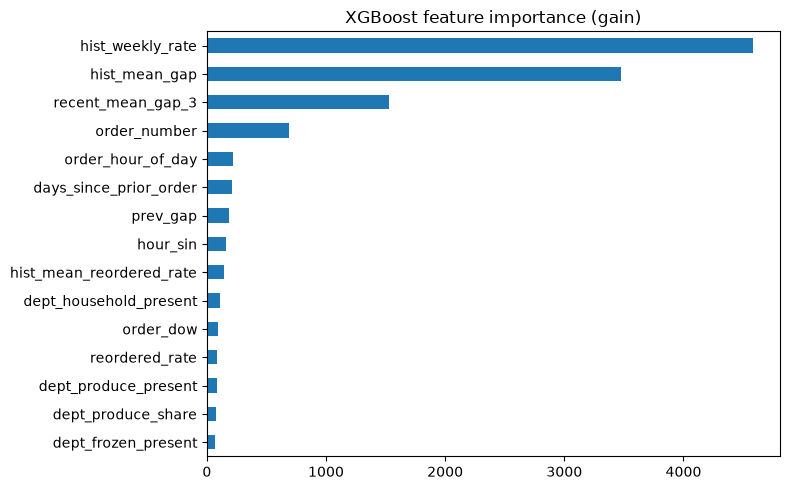

In [ ]:
# Study the top features of the model.
importance = pd.Series(
    xgb_model.get_booster().get_score(importance_type="gain")
).sort_values(ascending=False)

importance.head(15).sort_values().plot.barh(
    figsize=(8, 5),
    title="XGBoost feature importance (gain)"
)
plt.tight_layout()
plt.show()

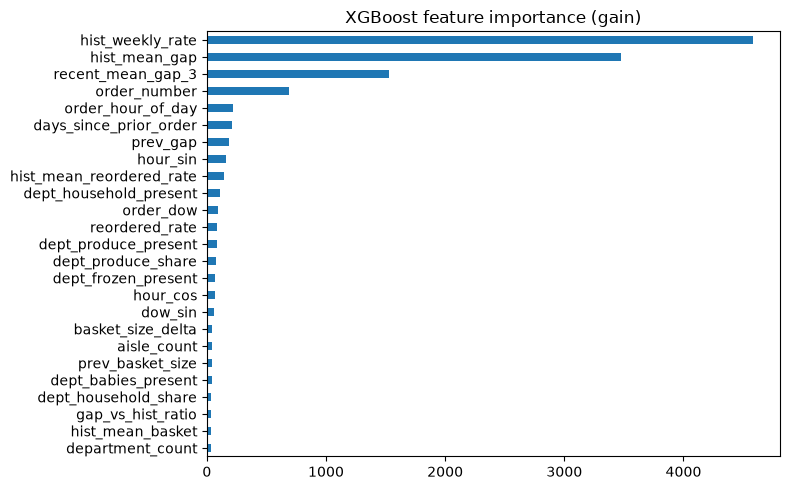

In [58]:
# Study all features of the model.
importance = pd.Series(
    xgb_model.get_booster().get_score(importance_type="gain")
).sort_values(ascending=False)

importance.head(25).sort_values().plot.barh(
    figsize=(8, 5),
    title="XGBoost feature importance (gain)"
)
plt.tight_layout()
plt.show()

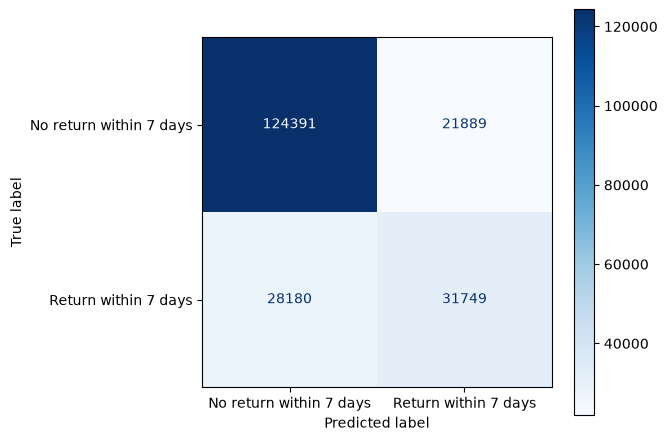

In [59]:
# Inspect mistakes in the model (predicted returns that didn't happen and missed returns).
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    xgb_val_pred,
    display_labels=["No return within 7 days", "Return within 7 days"],
    cmap="Blues"
)
plt.tight_layout()
plt.show()

In [61]:
# Precision and recall
from sklearn.metrics import classification_report

print(classification_report(
    y_val,
    xgb_val_pred,
    target_names=["No return within 7 days", "Return within 7 days"],
    digits=3
))

                         precision    recall  f1-score   support

No return within 7 days      0.815     0.850     0.832    146280
   Return within 7 days      0.592     0.530     0.559     59929

               accuracy                          0.757    206209
              macro avg      0.704     0.690     0.696    206209
           weighted avg      0.750     0.757     0.753    206209



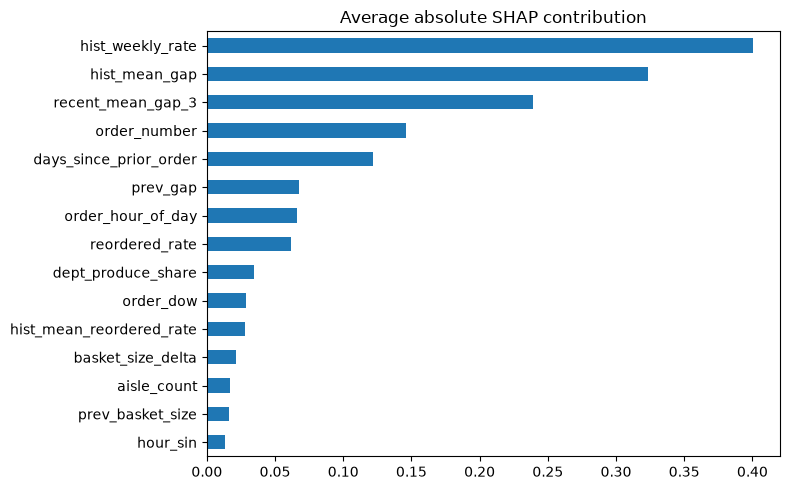

In [62]:
# SHAP Explanations
from xgboost import DMatrix

sample = X_val.sample(n=min(1000, len(X_val)), random_state=42)

contributions = xgb_model.get_booster().predict(
    DMatrix(sample),
    pred_contribs=True,
    iteration_range=(0, xgb_model.best_iteration + 1)
)

# The final column is the baseline contribution, not a feature.
shap_values = pd.DataFrame(
    contributions[:, :-1],
    columns=sample.columns,
    index=sample.index
)

shap_values.abs().mean().nlargest(15).sort_values().plot.barh(
    figsize=(8, 5),
    title="Average absolute SHAP contribution"
)
plt.tight_layout()
plt.show()